# Modelado · Créditos vehiculares
**Tarea 4 del reto · Soporte 4 · Rol: Ciencia de datos · CRISP-ML(Q) fase 3**

En el análisis exploratorio vimos que el riesgo existe, pero repartido en muchas señales pequeñas, y que la regla del buró no distingue a la mitad de los clientes. Aquí construimos un modelo que combine esas señales y lo ponemos a prueba en un mes que nunca vio.

**El resultado, en corto:** en octubre no pagaron 23,5 de cada 100 clientes. Si el modelo hubiera elegido a quién aprobar, dejando fuera al 12 % más riesgoso, no habrían pagado 21,4 de cada 100. Y con el mismo límite de impago, el modelo aprueba 2,6 veces más clientes que la regla del buró.

**Cómo lo hicimos, sin hacernos trampa:** el modelo nunca ve los datos con los que lo evaluamos.

| Etapa | Aprende con | Lo probamos en | Para qué |
|---|---|---|---|
| Ajuste | Agosto | Septiembre | Elegir variables y configuración |
| Prueba | Agosto y septiembre | **Octubre** (una sola vez) | Los resultados que reportamos |
| Producción | Agosto a octubre | Noviembre (sin respuesta) | El modelo que usa el tablero |

Probamos tres modelos: **gradient boosting** (el que mejor ordena, para Ventas), **regresión logística** (la que mejor se explica, para Riesgo) y **Random Forest** (como comparación). Este notebook usa las funciones de `modelado.py`, con las mismas semillas y los mismos resultados.

In [1]:
import os, sys, json, itertools, time, warnings
import numpy as np
import pandas as pd
sys.path.insert(0, os.path.abspath("."))
import modelado as m            # funciones: construir, probar, metricas, regla_buro, aprobados_al
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
prep, ing = m.prep, m.ing
LIMITE, APROBACION = m.LIMITE, m.APROBACION
TABLAS = os.path.join("salidas", "tablas")
os.makedirs(TABLAS, exist_ok=True)
print(f"Meta CN2: impago de los aprobados < {LIMITE:.2%} · Meta CN1: aprobar >= {APROBACION:.0%}")

Meta CN2: impago de los aprobados < 21.71% · Meta CN1: aprobar >= 90%


## 0 · Datos limpios (versión 1) y partición por tiempo
`BRANCH_ID` y `MANUFACTURER_ID` se leen como texto (igual que en la limpieza). `SUPPLIER_ID` se trae del original solo para probar si aporta.

In [2]:
tipos = {"BRANCH_ID": str, "MANUFACTURER_ID": str}
train = pd.read_csv("../limpieza_datos/datos_v1/train_limpio.csv", dtype=tipos)
crudo = prep.estandarizar_estructura(pd.read_csv("../train.csv"))[["UNIQUEID", "SUPPLIER_ID"]]
train = train.merge(crudo.astype({"SUPPLIER_ID": str}), on="UNIQUEID", how="left", validate="1:1")

y = train["LOAN_DEFAULT"]
ago, sep, octu = train["MES"].eq(8), train["MES"].eq(9), train["MES"].eq(10)
X_ago, y_ago = train[ago], y[ago]
X_sep, y_sep = train[sep], y[sep]
X_as, y_as = train[ago | sep], y[ago | sep]
X_oct, y_oct = train[octu], y[octu]
monto_oct = X_oct["DISBURSED_AMOUNT"]

pd.DataFrame({"créditos": [len(X_ago), len(X_sep), len(X_as), len(X_oct)],
              "impago (%)": [100 * v.mean() for v in (y_ago, y_sep, y_as, y_oct)]},
             index=["Agosto (ajuste)", "Septiembre (ajuste)", "Ago+Sep (entrenamiento)", "Octubre (prueba)"]).round(2)

,créditos,impago (%)
Agosto (ajuste),68002,21.57
Septiembre (ajuste),66788,19.19
Ago+Sep (entrenamiento),134790,20.39
Octubre (prueba),98364,23.51


## 1 · Referencias (CML1): clasificador trivial y regla del buró
La regla del buró usa como probabilidad el impago de cada categoría del buró en agosto-septiembre. Solo puede aprobar categorías completas.

In [3]:
resultados = {}
resultados["Trivial"] = m.metricas(y_oct, np.full(len(y_oct), y_as.mean()), monto_oct)
p_buro, n_buro, puntos_buro = m.regla_buro(X_as["CNS_GRUPO"], y_as, X_oct["CNS_GRUPO"], y_oct)
resultados["Regla buró"] = m.metricas(y_oct, p_buro, monto_oct)
resultados["Regla buró"].update(Max_aprobados_CN2=n_buro, Max_aprob_pct_CN2=n_buro / len(y_oct))
pd.DataFrame(resultados).T[["AUC", "KS", "Max_aprobados_CN2", "Max_aprob_pct_CN2"]].round(4)

,AUC,KS,Max_aprobados_CN2,Max_aprob_pct_CN2
Trivial,0.5,0.0,24248,0.246513
Regla buró,0.554497,0.07445,34467,0.350403


Empezamos por medir la vara con la que nos vamos a comparar. La regla del buró casi no supera a una moneda al aire (AUC de 0,554, donde 0,5 es azar). Para que el impago de los aprobados quede por debajo de 21,71 %, solo puede aprobar a 34 467 clientes, apenas el 35 % de octubre. No puede aprobar más porque, para ella, todos los clientes sin historial son iguales.

## 2 · Ingeniería de características (ajuste: agosto → septiembre)
Se parte de las 15 variables de la Fase 2 y se prueba agregar: `TIENE_MORA`, `CONSULTO_BURO`, `PROP_MORA` (variables nuevas) y `SUPPLIER_ID` agrupado. Un cambio se acepta solo si el AUC promedio sube al menos 0,002.

In [4]:
filas = []
for nuevas, prov in itertools.product([False, True], [False, True]):
    fila = {"nuevas": nuevas, "SUPPLIER_ID": prov}
    for tipo, params in [("logistica", {"C": 1.0}), ("boosting", {})]:
        _, p = m.probar(tipo, X_ago, y_ago, X_sep, nuevas, prov, **params)
        fila[f"AUC_sep_{tipo}"] = roc_auc_score(y_sep, p)
    fila["AUC_promedio"] = (fila["AUC_sep_logistica"] + fila["AUC_sep_boosting"]) / 2
    filas.append(fila)
variantes = pd.DataFrame(filas)
base = variantes.iloc[0]
mejor = variantes.loc[variantes["AUC_promedio"].idxmax()]
if mejor["AUC_promedio"] - base["AUC_promedio"] < m.MEJORA_MINIMA:
    mejor = base
NUEVAS, PROV = bool(mejor["nuevas"]), bool(mejor["SUPPLIER_ID"])
entrada = m.columnas(NUEVAS, PROV)[0]
print(f"Decisión: variables nuevas = {NUEVAS} · SUPPLIER_ID = {PROV} · {len(entrada)} variables")
variantes.round(4)

Decisión: variables nuevas = False · SUPPLIER_ID = False · 15 variables


,nuevas,SUPPLIER_ID,AUC_sep_logistica,AUC_sep_boosting,AUC_promedio
0,False,False,0.6512,0.6559,0.6535
1,False,True,0.6515,0.6537,0.6526
2,True,False,0.6516,0.6560,0.6538
3,True,True,0.6520,0.6534,0.6527


Probamos si valía la pena sumar tres variables nuevas (tener alguna cuenta en mora, haber consultado el buró y la proporción de cuentas en mora) y el concesionario. Ninguna mejoró el resultado en septiembre lo suficiente; el concesionario incluso lo empeoró, porque con casi 3 000 concesionarios distintos el modelo tiende a memorizar en vez de aprender. Nos quedamos con las 15 variables de la limpieza: un modelo más simple que rinde igual.

## 3 · Hiperparámetros (ajuste: agosto → septiembre, métrica AUC)
Métodos de estimación: regresión logística con regularización L2 y L1, regresión logística sobre WoE (scorecard), gradient boosting con *early stopping* y Random Forest.

In [5]:
rejillas = {
    "logistica": [{"C": c, "l1_ratio": 0.0} for c in (0.01, 0.1, 1.0)]
                 + [{"C": c, "l1_ratio": 1.0, "solver": "liblinear"} for c in (0.01, 0.1, 1.0)],
    "logistica_woe": [{"C": c, "l1_ratio": 0.0} for c in (0.01, 0.1, 1.0)],
    "boosting": [dict(learning_rate=lr, max_leaf_nodes=h, min_samples_leaf=n, l2_regularization=l2)
                 for lr, h, n, l2 in itertools.product((0.05, 0.1), (15, 31), (100, 400), (0.0, 1.0))],
    "bosque": [dict(min_samples_leaf=n, max_features=f) for n in (50, 200) for f in ("sqrt", 0.3)],
}
busqueda = []
for tipo, rejilla in rejillas.items():
    for params in rejilla:
        t0 = time.perf_counter()
        _, p = m.probar(tipo, X_ago, y_ago, X_sep, NUEVAS, PROV, **params)
        busqueda.append({"modelo": tipo, "params": json.dumps(params), "AUC_sep": roc_auc_score(y_sep, p),
                         "segundos": time.perf_counter() - t0})
busqueda = pd.DataFrame(busqueda)
mejores = {t: json.loads(g.loc[g["AUC_sep"].idxmax(), "params"]) for t, g in busqueda.groupby("modelo")}
auc_tipo = busqueda.groupby("modelo")["AUC_sep"].max()
RIESGO = "logistica_woe" if auc_tipo["logistica_woe"] > auc_tipo["logistica"] else "logistica"
print(f"{len(busqueda)} modelos entrenados en {busqueda['segundos'].sum():.0f} s")
print("Regresión logística para Riesgo:", RIESGO)
print(json.dumps(mejores, indent=1))
busqueda.sort_values("AUC_sep", ascending=False).groupby("modelo").head(3).round(4)

29 modelos entrenados en 65 s
Regresión logística para Riesgo: logistica
{
 "boosting": {
  "learning_rate": 0.05,
  "max_leaf_nodes": 15,
  "min_samples_leaf": 100,
  "l2_regularization": 0.0
 },
 "bosque": {
  "min_samples_leaf": 50,
  "max_features": 0.3
 },
 "logistica": {
  "C": 0.1,
  "l1_ratio": 0.0
 },
 "logistica_woe": {
  "C": 1.0,
  "l1_ratio": 0.0
 }
}


,modelo,params,AUC_sep,segundos
9,boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15, ...",0.6578,1.8005
14,boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31, ...",0.6577,2.0180
20,boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15, ""...",0.6576,1.1240
1,logistica,"{""C"": 0.1, ""l1_ratio"": 0.0}",0.6515,1.7099
5,logistica,"{""C"": 1.0, ""l1_ratio"": 1.0, ""solver"": ""libline...",0.6514,7.0383
2,logistica,"{""C"": 1.0, ""l1_ratio"": 0.0}",0.6512,1.7349
8,logistica_woe,"{""C"": 1.0, ""l1_ratio"": 0.0}",0.6403,0.4675
26,bosque,"{""min_samples_leaf"": 50, ""max_features"": 0.3}",0.6401,6.9579
7,logistica_woe,"{""C"": 0.1, ""l1_ratio"": 0.0}",0.6396,0.4788
25,bosque,"{""min_samples_leaf"": 50, ""max_features"": ""sqrt""}",0.6392,5.9485


Aquí entrenamos 29 versiones de los modelos con distintas configuraciones. Las diferencias entre ellas son de milésimas, y casi siempre ganó la versión más conservadora: cuando el modelo se vuelve más complejo empieza a aprenderse de memoria agosto y deja de funcionar igual de bien en septiembre. Para nosotros la conclusión es clara: el límite lo pone la información que traen los datos, no el algoritmo.

## 4 · Prueba final: entrena con agosto + septiembre, evalúa en octubre (CML1, CML2)

In [6]:
nombres = {"logistica": "Logística one-hot", "logistica_woe": "Logística WoE",
           "boosting": "Gradient boosting", "bosque": "Random Forest"}
modelos_oct, probs = {}, {"Regla buró": p_buro}
for tipo, nombre in nombres.items():
    modelos_oct[tipo], probs[nombre] = m.probar(tipo, X_as, y_as, X_oct, NUEVAS, PROV, **mejores[tipo])
    resultados[nombre] = m.metricas(y_oct, probs[nombre], monto_oct)
for tipo in ["boosting", RIESGO]:                     # calibración sigmoide (CML2)
    base_modelo, _ = m.construir(tipo, NUEVAS, PROV, **mejores[tipo])
    cal = CalibratedClassifierCV(base_modelo, method="sigmoid", cv=3).fit(X_as[entrada], y_as)
    probs[nombres[tipo] + " calibrada"] = cal.predict_proba(X_oct[entrada])[:, 1]
    resultados[nombres[tipo] + " calibrada"] = m.metricas(y_oct, probs[nombres[tipo] + " calibrada"], monto_oct)
comparacion = pd.DataFrame(resultados).T
comparacion[["AUC", "PR_AUC", "KS", "Brier", "Prob_media", "Impago_aprobados_90", "Cumple_CN2",
             "Impagos_evitados", "Buenos_rechazados", "Monto_evitado_CE1", "Max_aprobados_CN2"]].round(4)

,AUC,PR_AUC,KS,Brier,Prob_media,Impago_aprobados_90,Cumple_CN2,Impagos_evitados,Buenos_rechazados,Monto_evitado_CE1,Max_aprobados_CN2
Trivial,0.5,0.235147,0.0,0.180831,0.20388,0.233395,False,2468,7368,141383158.0,24248
Regla buró,0.554497,0.263218,0.07445,0.179644,0.203759,0.226245,False,3101,6735,182172067.0,34467
Logística one-hot,0.638957,0.337865,0.203576,0.173406,0.201166,0.217163,False,3905,5931,238813228.0,88494
Logística WoE,0.63104,0.32815,0.190177,0.174294,0.201033,0.21862,False,3776,6060,226000628.0,87428
Gradient boosting,0.647813,0.344855,0.217687,0.17263,0.198003,0.21696,True,3923,5913,237111562.0,88663
Random Forest,0.634893,0.334156,0.196789,0.173841,0.202395,0.218191,False,3814,6022,234841552.0,87790
Gradient boosting calibrada,0.64748,0.346233,0.215223,0.17281,0.198128,0.216632,True,3952,5884,240479880.0,88821
Logística one-hot calibrada,0.638222,0.337448,0.201908,0.173643,0.199953,0.217445,False,3880,5956,236901694.0,88205


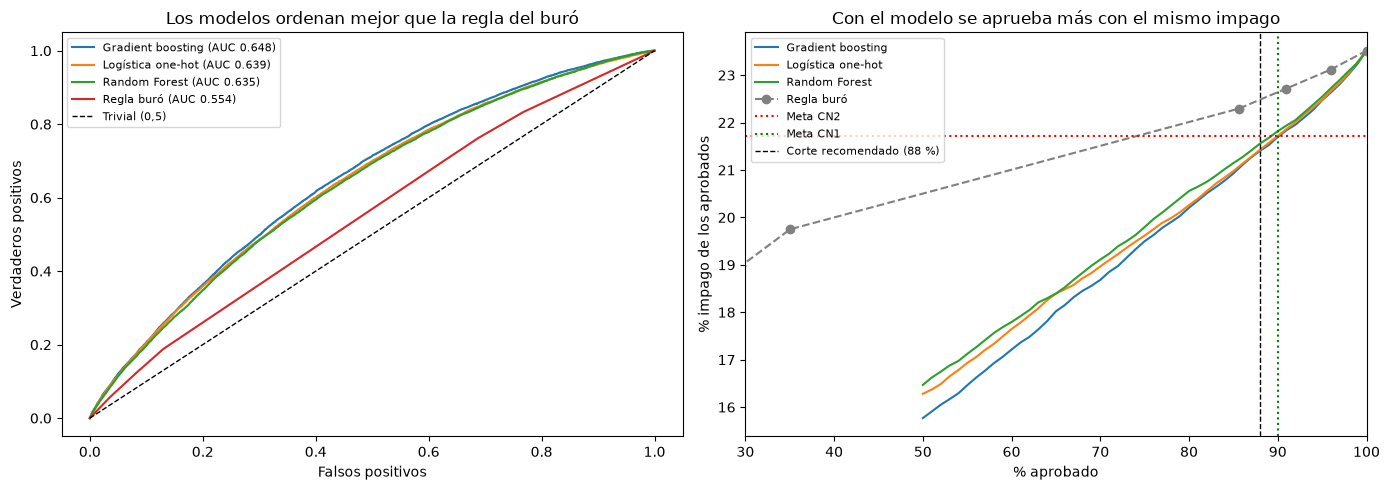

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nombre in ["Gradient boosting", nombres[RIESGO], "Random Forest", "Regla buró"]:
    fpr, tpr, _ = roc_curve(y_oct, probs[nombre])
    ax[0].plot(fpr, tpr, label=f"{nombre} (AUC {resultados[nombre]['AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Trivial (0,5)")
ax[0].set(xlabel="Falsos positivos", ylabel="Verdaderos positivos", title="Los modelos ordenan mejor que la regla del buró"); ax[0].legend(fontsize=8)

tasas = np.round(np.arange(0.50, 1.0001, 0.01), 2)
for nombre in ["Gradient boosting", nombres[RIESGO], "Random Forest"]:
    ax[1].plot(tasas * 100, [100 * y_oct.to_numpy()[m.aprobados_al(probs[nombre], t)].mean() for t in tasas], label=nombre)
ax[1].plot([100 * x for _, x, _ in puntos_buro], [100 * z for _, _, z in puntos_buro], "o--", color="gray", label="Regla buró")
ax[1].axhline(LIMITE * 100, color="red", ls=":", label="Meta CN2"); ax[1].axvline(90, color="green", ls=":", label="Meta CN1")
ax[1].axvline(88, color="black", ls="--", lw=1, label="Corte recomendado (88 %)")
ax[1].set(xlabel="% aprobado", ylabel="% impago de los aprobados", title="Con el modelo se aprueba más con el mismo impago", xlim=(30, 100))
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**El gráfico de la derecha es el que mejor resume el proyecto.** Cada línea muestra qué pasa con el impago de los aprobados según cuántas solicitudes se aprueben. Las líneas de los modelos van siempre por debajo de la regla del buró: para aprobar la misma cantidad de gente, el modelo deja pasar menos clientes que no pagarán.

En números:
- **Para Riesgo:** aprobando 90 de cada 100 solicitudes, no pagarían 21,7 de cada 100 aprobados (sin el modelo fueron 23,5). Aprobando 88 de cada 100, bajaría a 21,4.
- **Para Ventas:** con el mismo límite de impago, el modelo puede aprobar 88 663 créditos y la regla solo 34 467. Son 54 196 clientes viables que hoy se quedarían fuera.

A la izquierda, la curva ROC dice lo mismo de otra forma: los tres modelos quedan muy cerca entre sí y claramente por encima de la regla.

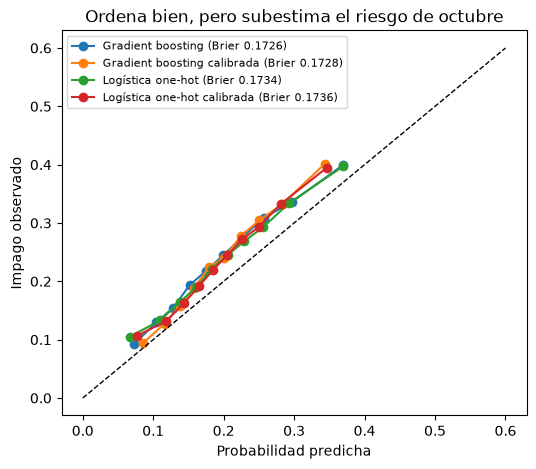

Probabilidad media predicha (boosting): 19.80% · impago real: 23.51%


In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
for nombre in ["Gradient boosting", "Gradient boosting calibrada", nombres[RIESGO], nombres[RIESGO] + " calibrada"]:
    frac, media = calibration_curve(y_oct, probs[nombre], n_bins=10, strategy="quantile")
    ax.plot(media, frac, "o-", label=f"{nombre} (Brier {resultados[nombre]['Brier']:.4f})")
ax.plot([0, 0.6], [0, 0.6], "k--", lw=1)
ax.set(xlabel="Probabilidad predicha", ylabel="Impago observado", title="Ordena bien, pero subestima el riesgo de octubre"); ax.legend(fontsize=8); plt.show()
print(f"Probabilidad media predicha (boosting): {probs['Gradient boosting'].mean():.2%} · impago real: {y_oct.mean():.2%}")

Este gráfico muestra una debilidad que preferimos decir de frente: **el modelo se quedó corto en octubre.** Esperaba que no pagaran 19,8 de cada 100 clientes y en realidad no pagaron 23,5. Es decir, el riesgo real fue cerca de 1,2 veces lo que el modelo calculó.

¿Por qué? Porque aprendió en agosto y septiembre, que fueron meses más tranquilos, y octubre fue un mes peor. Lo importante es que **el orden sí lo acierta**: los clientes que el modelo pone como más riesgosos son, efectivamente, los que más dejan de pagar (los puntos forman una línea recta). Por eso las decisiones del tipo "aprobar al 88 % con menos riesgo" siguen funcionando. Lo que no se puede tomar al pie de la letra es la probabilidad exacta: si el tablero dice que un cliente tiene 80 % de probabilidad de pagar, en un mes como octubre la real habría sido algo menor. En un uso real, el modelo debería ajustarse cada mes con los datos más recientes.

## 5 · Robustez 1: ¿el cumplimiento de CN2 es sólido? (bootstrap)
Se remuestrean los créditos de octubre 1 000 veces (con reemplazo), manteniendo el corte del modelo, para estimar el intervalo de confianza del 95 % del impago de los aprobados y del AUC.

In [9]:
rng = np.random.default_rng(m.SEMILLA)
y_arr, n = y_oct.to_numpy(), len(y_oct)
B, B_AUC = 1000, 200
muestras = [rng.integers(0, n, n) for _ in range(B)]
filas = []
for nombre in ["Gradient boosting", nombres[RIESGO]]:
    p = probs[nombre]
    aucs = [roc_auc_score(y_arr[i], p[i]) for i in muestras[:B_AUC]]
    for tasa in (0.85, 0.88, 0.90):
        aprob = m.aprobados_al(p, tasa)
        imp = np.array([y_arr[i][aprob[i]].mean() for i in muestras])
        filas.append({"modelo": nombre, "% aprobado": int(tasa * 100),
                      "impago aprobados (%)": 100 * y_arr[aprob].mean(),
                      "IC95 inferior (%)": 100 * np.percentile(imp, 2.5),
                      "IC95 superior (%)": 100 * np.percentile(imp, 97.5),
                      "P(impago < meta)": (imp < LIMITE).mean(),
                      "AUC IC95": f"{np.percentile(aucs, 2.5):.3f} – {np.percentile(aucs, 97.5):.3f}"})
robustez = pd.DataFrame(filas)
robustez.to_csv(os.path.join(TABLAS, "robustez_bootstrap.csv"), index=False)
robustez.round(3)

,modelo,% aprobado,impago aprobados (%),IC95 inferior (%),IC95 superior (%),P(impago < meta),AUC IC95
0,Gradient boosting,85,20.927,20.648,21.216,1.000,0.644 – 0.652
1,Gradient boosting,88,21.402,21.127,21.690,0.981,0.644 – 0.652
2,Gradient boosting,90,21.696,21.425,21.973,0.523,0.644 – 0.652
3,Logística one-hot,85,20.977,20.690,21.263,1.000,0.635 – 0.643
4,Logística one-hot,88,21.426,21.142,21.710,0.974,0.635 – 0.643
5,Logística one-hot,90,21.716,21.433,22.012,0.454,0.635 – 0.643


Queríamos saber si el 21,70 % era un resultado sólido o un golpe de suerte, porque la meta es 21,71 %. Así que repetimos la medición 1 000 veces sobre muestras distintas de octubre.

La respuesta es que **aprobando el 90 %, cumplir la meta es una moneda al aire**: pasa en 52 de cada 100 repeticiones. **Aprobando el 88 %, se cumple en 98 de cada 100.** Dicho de otra forma: las metas de Ventas (aprobar al menos el 90 %) y de Riesgo (impago menor a 21,71 %) no se pueden garantizar al mismo tiempo. Nuestra recomendación es aprobar alrededor del 88 %, que cumple la meta de Riesgo con mucha seguridad y conserva casi 9 de cada 10 aprobaciones. La decisión final es de las gerencias.

## 6 · Robustez 2: ¿cuánto depende el modelo de la sucursal y de la edad?
La sucursal es la segunda variable más importante y la edad es sensible (equidad, R11). Se reentrena sin cada una (agosto + septiembre → octubre) para medir cuánto se pierde.

In [10]:
def probar_sin(tipo, quitar):
    """Entrena quitando variables (modifica temporalmente las listas de modelado.py)."""
    cat0, num0 = m.CAT_BASE, m.NUM_BASE
    m.CAT_BASE = [c for c in cat0 if c not in quitar]
    m.NUM_BASE = [c for c in num0 if c not in quitar]
    try:
        return m.probar(tipo, X_as, y_as, X_oct, NUEVAS, PROV, **mejores[tipo])[1]
    finally:
        m.CAT_BASE, m.NUM_BASE = cat0, num0

filas = []
for tipo in ["boosting", RIESGO]:
    for etiqueta, quitar in [("Modelo completo (15)", []), ("Sin sucursal", ["BRANCH_ID"]), ("Sin edad", ["EDAD"])]:
        p = probs[nombres[tipo]] if not quitar else probar_sin(tipo, quitar)
        r = m.metricas(y_oct, p, monto_oct)
        filas.append({"modelo": nombres[tipo], "variante": etiqueta, "AUC": r["AUC"], "KS": r["KS"],
                      "impago aprobados 90 (%)": 100 * r["Impago_aprobados_90"],
                      "max aprobados con impago < meta": r["Max_aprobados_CN2"]})
sensibilidad = pd.DataFrame(filas)
sensibilidad.to_csv(os.path.join(TABLAS, "sensibilidad_variables.csv"), index=False)
sensibilidad.round(4)

,modelo,variante,AUC,KS,impago aprobados 90 (%),max aprobados con impago < meta
0,Gradient boosting,Modelo completo (15),0.6478,0.2177,21.6960,88663
1,Gradient boosting,Sin sucursal,0.6290,0.1877,21.8100,87651
2,Gradient boosting,Sin edad,0.6457,0.2131,21.6530,88924
3,Logística one-hot,Modelo completo (15),0.6390,0.2036,21.7163,88494
4,Logística one-hot,Sin sucursal,0.6201,0.1711,21.9196,86717
5,Logística one-hot,Sin edad,0.6371,0.2004,21.7502,88255


También quisimos ver de qué depende el modelo. Si le quitamos la sucursal, pierde bastante (el AUC baja de 0,648 a 0,629) y ya no cumple la meta: la sucursal trae información que ninguna otra variable reemplaza.

Si le quitamos la edad, en cambio, casi no cambia nada (AUC de 0,646 y el mismo impago de los aprobados). Esto es importante: **podemos dejar de usar la edad sin perder casi nada**, y así evitar que el modelo trate distinto a las personas por su edad. Lo dejamos como recomendación para la siguiente versión.

## 6b · ¿Y si balanceamos las clases?

De cada 100 clientes, 78 pagan y 22 no. Una práctica común es **balancear** las clases para que el modelo "preste más atención" a los que no pagan. Quisimos comprobar con datos si eso nos ayudaba, en lugar de suponerlo.

Probamos dos formas, con la misma validación de siempre (aprender con agosto y septiembre, probar en octubre):

| Variante | Qué hace |
|---|---|
| **Sin balancear** | El modelo actual: aprende con la proporción real de clientes |
| **Pesos por clase** | Cada cliente que no pagó cuenta unas 3,6 veces más al entrenar (`class_weight="balanced"`) |
| **Submuestreo 50/50** | Se eliminan al azar clientes que pagaron hasta quedar mitad y mitad (se pierden unos 80 000 clientes reales) |

No probamos SMOTE, que inventa clientes sintéticos mezclando clientes reales: con variables como la sucursal (82 categorías) genera combinaciones que no existen, y en crédito es difícil de defender ante una auditoría.

In [11]:
rng = np.random.default_rng(m.SEMILLA)
y_np = y_as.to_numpy()
malos, buenos = np.where(y_np == 1)[0], np.where(y_np == 0)[0]
sub = np.sort(np.concatenate([malos, rng.choice(buenos, size=len(malos), replace=False)]))
X_sub, y_sub = X_as.iloc[sub], y_as.iloc[sub]
print(f"Entrenamiento original: {len(y_as):,} clientes ({y_as.mean():.1%} no pagan)")
print(f"Submuestreo 50/50:      {len(y_sub):,} clientes ({y_sub.mean():.1%} no pagan) · se descartan {len(y_as) - len(y_sub):,}")

filas, probs_bal = [], {}
for tipo in ["boosting", RIESGO]:
    variantes = {
        "Sin balancear": probs[nombres[tipo]],
        "Pesos por clase": m.probar(tipo, X_as, y_as, X_oct, NUEVAS, PROV, **mejores[tipo], class_weight="balanced")[1],
        "Submuestreo 50/50": m.probar(tipo, X_sub, y_sub, X_oct, NUEVAS, PROV, **mejores[tipo])[1],
    }
    for variante, p in variantes.items():
        probs_bal[(nombres[tipo], variante)] = p
        r = m.metricas(y_oct, p, monto_oct, tasa=0.88)
        filas.append({"modelo": nombres[tipo], "variante": variante, "AUC": r["AUC"], "KS": r["KS"],
                      "PR-AUC": r["PR_AUC"], "Brier": r["Brier"],
                      "prob. media predicha (%)": 100 * r["Prob_media"],
                      "impago aprobados al 88 % (%)": 100 * r["Impago_aprobados_88"],
                      "créditos aprobables con impago < meta": r["Max_aprobados_CN2"]})
balanceo = pd.DataFrame(filas)
balanceo.to_csv(os.path.join(TABLAS, "balanceo_clases.csv"), index=False)
print(f"Impago real de octubre: {100 * y_oct.mean():.2f} %")
balanceo.round(4)

Entrenamiento original: 134,790 clientes (20.4% no pagan)
Submuestreo 50/50:      54,962 clientes (50.0% no pagan) · se descartan 79,828


Impago real de octubre: 23.51 %


,modelo,variante,AUC,KS,PR-AUC,Brier,prob. media predicha (%),impago aprobados al 88 % (%),créditos aprobables con impago < meta
0,Gradient boosting,Sin balancear,0.6478,0.2177,0.3449,0.1726,19.8003,21.4025,88663
1,Gradient boosting,Pesos por clase,0.6470,0.2162,0.3438,0.2263,46.5165,21.4233,88611
2,Gradient boosting,Submuestreo 50/50,0.6462,0.2142,0.3436,0.2296,46.9911,21.3667,88644
3,Logística one-hot,Sin balancear,0.6390,0.2036,0.3379,0.1734,20.1166,21.4256,88494
4,Logística one-hot,Pesos por clase,0.6391,0.2030,0.3376,0.2319,47.3735,21.4314,88472
5,Logística one-hot,Submuestreo 50/50,0.6384,0.2026,0.3369,0.2328,47.5396,21.4244,88320


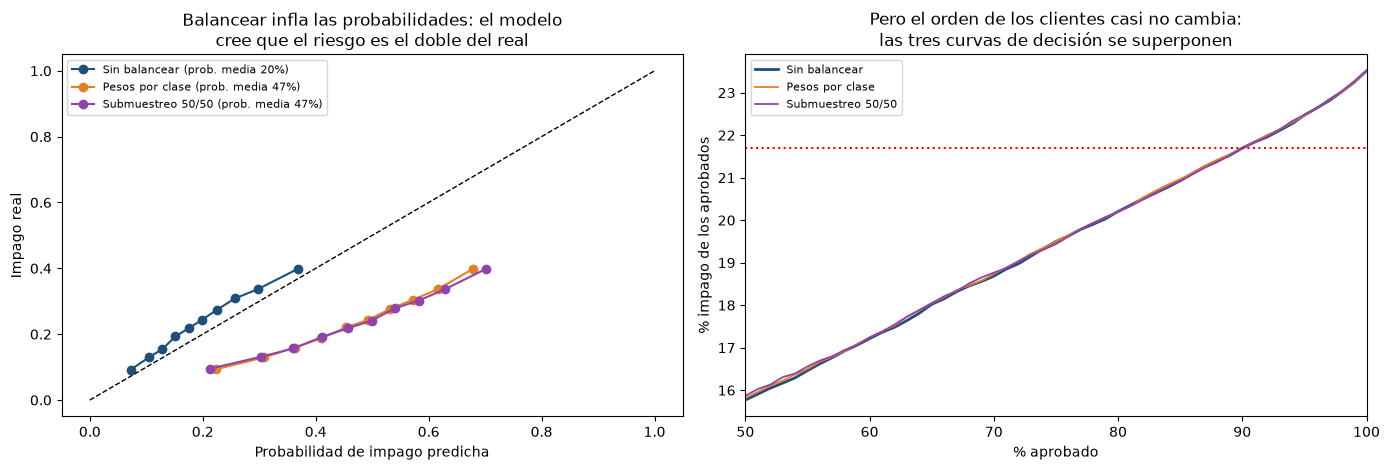

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
colores = {"Sin balancear": "#1F4E79", "Pesos por clase": "#E67E22", "Submuestreo 50/50": "#8E44AD"}
for variante, color in colores.items():
    p = probs_bal[("Gradient boosting", variante)]
    frac, media = calibration_curve(y_oct, p, n_bins=10, strategy="quantile")
    ax[0].plot(media, frac, "o-", color=color, label=f"{variante} (prob. media {p.mean():.0%})")
    curva_b = [100 * y_oct.to_numpy()[m.aprobados_al(p, t)].mean() for t in tasas]
    ax[1].plot(tasas * 100, curva_b, color=color, label=variante, lw=2 if variante == "Sin balancear" else 1.3)
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(xlabel="Probabilidad de impago predicha", ylabel="Impago real",
          title="Balancear infla las probabilidades: el modelo\ncree que el riesgo es el doble del real")
ax[1].axhline(LIMITE * 100, color="red", ls=":")
ax[1].set(xlabel="% aprobado", ylabel="% impago de los aprobados", xlim=(50, 100),
          title="Pero el orden de los clientes casi no cambia:\nlas tres curvas de decisión se superponen")
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("salidas/graficos/balanceo_clases.png", dpi=150); plt.show()

**Qué vemos:**
- **El orden de los clientes no cambia.** El AUC queda prácticamente igual en las tres variantes (0,648 sin balancear, 0,647 con pesos y 0,646 con submuestreo en el gradient boosting), y las curvas de decisión del gráfico de la derecha se superponen. Aprobando el 88 %, el impago de los aprobados es 21,40 % sin balancear, 21,42 % con pesos y 21,37 % con submuestreo: diferencias de centésimas, dentro del margen de error.
- **Las probabilidades se arruinan.** Sin balancear, el modelo predice en promedio 19,8 % de impago (el real fue 23,5 %). Balanceado, predice **47 %: el doble del riesgo real**. Por eso el Brier empeora de 0,173 a 0,226 – 0,230, y en el gráfico de la izquierda las curvas balanceadas quedan muy por debajo de la diagonal.
- **El submuestreo además desperdicia datos:** para quedar 50/50 hay que descartar 79 828 clientes reales, el 59 % del entrenamiento.

**Qué significa:** balancear no le enseña nada nuevo al modelo; solo le cambia la escala a las probabilidades. Como nosotros decidimos **por orden** (aprobar el X % de menor riesgo), el balanceo no cambia ninguna decisión. Pero sí haría que el tablero le dijera a un gerente que un cliente tiene 50 % de probabilidad de no pagar cuando en realidad tiene cerca de 25 %. **Por eso no balanceamos:** el desbalance lo manejamos con métricas que no dependen de él (AUC, KS) y con el corte de negocio, y así las probabilidades siguen siendo interpretables.

## 7 · Explicabilidad: coeficientes (Riesgo) e importancia de variables (Ventas)

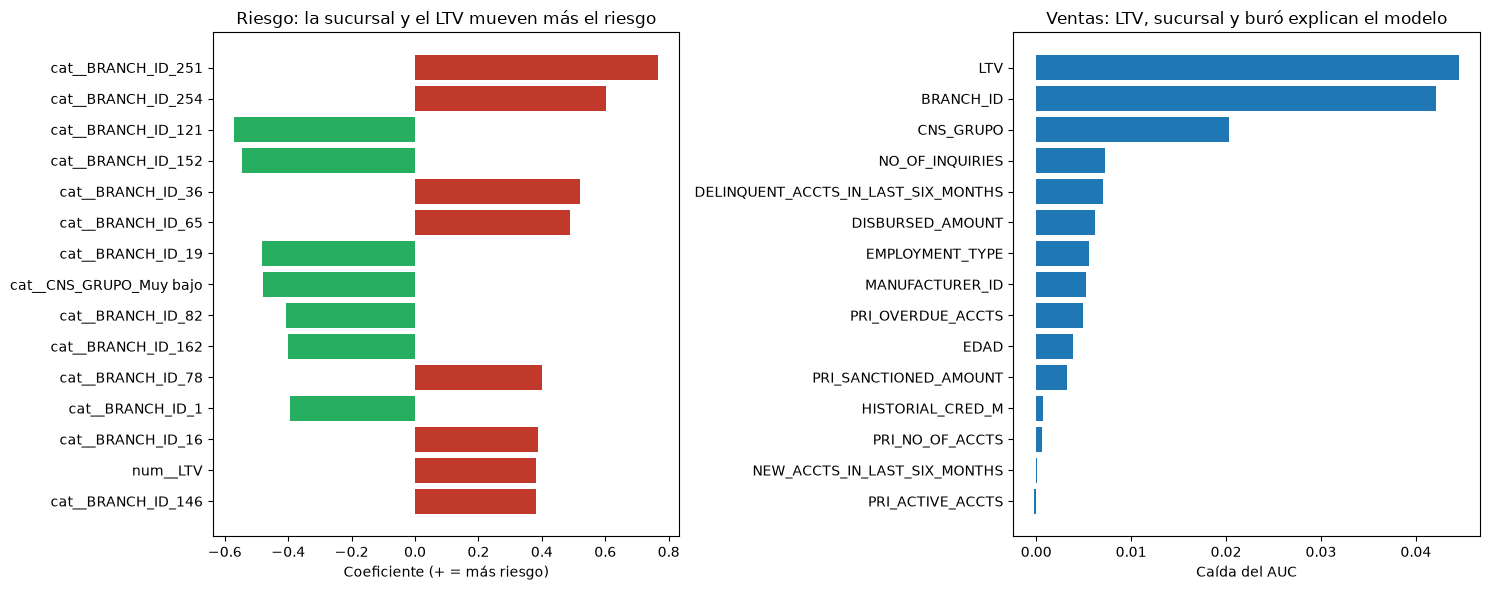

,variable,coeficiente,odds_ratio
59,cat__BRANCH_ID_251,0.767,2.154
60,cat__BRANCH_ID_254,0.601,1.825
31,cat__BRANCH_ID_121,-0.571,0.565
42,cat__BRANCH_ID_152,-0.547,0.579
70,cat__BRANCH_ID_36,0.520,1.682
79,cat__BRANCH_ID_65,0.490,1.632
51,cat__BRANCH_ID_19,-0.484,0.617
15,cat__CNS_GRUPO_Muy bajo,-0.479,0.619
94,cat__BRANCH_ID_82,-0.406,0.666
47,cat__BRANCH_ID_162,-0.400,0.670


In [13]:
lr = modelos_oct[RIESGO]
nombres_lr = lr[:-1].transform(X_oct[entrada].head(5)).columns
coef = pd.DataFrame({"variable": nombres_lr, "coeficiente": lr.named_steps["modelo"].coef_[0]})
coef["odds_ratio"] = np.exp(coef["coeficiente"])
coef = coef.reindex(coef["coeficiente"].abs().sort_values(ascending=False).index)

muestra = X_oct.sample(n=20000, random_state=m.SEMILLA)
imp = permutation_importance(modelos_oct["boosting"], muestra[entrada], y_oct.loc[muestra.index],
                             scoring="roc_auc", n_repeats=5, random_state=m.SEMILLA, n_jobs=1)
importancia = pd.DataFrame({"variable": entrada, "caida_AUC": imp.importances_mean}).sort_values("caida_AUC")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
top = coef.head(15).iloc[::-1]
ax[0].barh(top["variable"], top["coeficiente"], color=np.where(top["coeficiente"] > 0, "#c0392b", "#27ae60"))
ax[0].set(title="Riesgo: la sucursal y el LTV mueven más el riesgo", xlabel="Coeficiente (+ = más riesgo)")
ax[1].barh(importancia["variable"], importancia["caida_AUC"])
ax[1].set(title="Ventas: LTV, sucursal y buró explican el modelo", xlabel="Caída del AUC")
plt.tight_layout(); plt.show()
coef.head(10).round(3)

¿En qué se fija el modelo para decidir? Sobre todo en tres cosas: **cuánto del vehículo se financia** (LTV), **en qué sucursal** se origina el crédito y **la calificación del buró**. El resto de variables aporta poco una vez que el modelo ya conoce esas tres.

La regresión logística permite ponerle números: originar un crédito en la sucursal 251 multiplica las probabilidades relativas de no pagar por 2,2, mientras que la 121 las reduce a la mitad; tener buró "muy bajo" protege, y financiar más aumenta el riesgo. Así, Riesgo puede explicar por qué se rechaza a un cliente y Ventas sabe dónde crecer con menos riesgo. Recordemos que son asociaciones: el modelo no dice que la sucursal sea la causa.

## 8 · Equidad (R11): desempeño por edad y tipo de empleo

In [14]:
seg = X_oct.assign(GRUPO_EDAD=pd.cut(X_oct["EDAD"], [0, 25, 30, 35, 45, 120],
                                     labels=["18-25", "26-30", "31-35", "36-45", "46+"]))
aprob = m.aprobados_al(probs["Gradient boosting"], APROBACION)
filas = []
for col in ["GRUPO_EDAD", "EMPLOYMENT_TYPE"]:
    for g, idx in seg.groupby(col, observed=True).indices.items():
        yy = y_oct.to_numpy()[idx]
        filas.append({"segmento": col, "grupo": g, "créditos": len(idx), "impago real (%)": 100 * yy.mean(),
                      "AUC": roc_auc_score(yy, probs["Gradient boosting"][idx]),
                      "% aprobado": 100 * aprob[idx].mean(), "impago aprobados (%)": 100 * yy[aprob[idx]].mean()})
pd.DataFrame(filas).round(2)

,segmento,grupo,créditos,impago real (%),AUC,% aprobado,impago aprobados (%)
0,GRUPO_EDAD,18-25,23078,25.44,0.63,88.21,23.43
1,GRUPO_EDAD,26-30,19608,24.17,0.64,89.19,22.26
2,GRUPO_EDAD,31-35,16394,23.87,0.65,89.86,21.99
3,GRUPO_EDAD,36-45,24382,22.12,0.65,91.35,20.53
4,GRUPO_EDAD,46+,14902,21.55,0.67,91.79,19.98
5,EMPLOYMENT_TYPE,Salaried,40420,22.14,0.65,91.95,20.71
6,EMPLOYMENT_TYPE,Self employed,54373,24.56,0.65,88.51,22.45
7,EMPLOYMENT_TYPE,Sin dato,3571,23.19,0.62,90.65,21.84


Por último revisamos si el modelo trata parecido a los distintos grupos. A los jóvenes de 18 a 25 años y a los independientes les aprueba un poco menos (88 de cada 100 frente a 92 de cada 100 en los mayores de 46), lo cual sigue el impago real de esos grupos. Además, el modelo distingue un poco peor a los jóvenes. La diferencia es moderada, pero hay que vigilarla; quitar la edad, que casi no aporta, es la forma más directa de reducirla.

## Lo que concluimos
1. **El problema:** en octubre no pagaron 23,5 de cada 100 clientes, y la regla del buró no puede distinguir a la mitad de ellos porque no tienen historial.
2. **Lo que logra el modelo:** aprobando el 88 % de las solicitudes, el impago de los aprobados baja a 21,4 %, con 98 % de seguridad. Con el mismo límite de impago, aprueba 54 196 clientes viables más que la regla.
3. **Qué tan bueno es:** su capacidad de separar buenos y malos pagadores es moderada (AUC de 0,65), pero es 2,7 veces la de la regla. No pudimos subirla con ningún algoritmo: el techo lo ponen los datos, porque la mitad de los clientes no tiene historial y no tenemos su ingreso.
4. **Cómo usarlo:** el gradient boosting para decidir, la regresión logística para explicar cada decisión, un corte cercano al 88 % y revisión manual de los casos intermedios.
5. **Lo que hay que tener presente:** en meses malos se queda corto en el nivel de riesgo, depende de la sucursal, solo mira la primera cuota y solo conoce a clientes que ya fueron aprobados.